In [466]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [467]:
# Rogue AP detection as Anomaly with SVM (Support Vector Machine)
# Fix Old pipeline OneClass
# André L. S. Paula

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)
NORMAL_LABEL = 1
ROGUE_LABEL = -1
RANDOM_STATE = 42
data = pd.read_csv('/content/drive/MyDrive/datasets/dataset.csv')
data.shape

(357, 21)

In [468]:
print(data.columns.tolist())

['rogue', 'Dot11EltCountry', 'RSNVersion', 'rates', 'CapabilitiesMin_MPDCU_Start_Spacing', 'DSSS_CCK', 'Max_A_MSDU', 'Rx_STBC', 'Tx_STBC', 'Short_GI_40Mhz', 'Short_GI_20Mhz', 'SM_Power_Save', 'Supported_Channel_Width', 'LDPC_Coding_Capability', 'Min_MPDCU_Start_Spacing', 'Max_A_MPDU_Length_Exponent', 'TX_MCS_Set_Defined', 'RX_MSC_Bitmask', 'Compressed_Steering_n_Beamformer_Antennas_Supported', 'Receive_NDP', 'entropy']


In [469]:
print(data.dtypes)

rogue                                                    int64
Dot11EltCountry                                          int64
RSNVersion                                               int64
rates                                                    int64
CapabilitiesMin_MPDCU_Start_Spacing                      int64
DSSS_CCK                                                 int64
Max_A_MSDU                                               int64
Rx_STBC                                                  int64
Tx_STBC                                                  int64
Short_GI_40Mhz                                           int64
Short_GI_20Mhz                                           int64
SM_Power_Save                                            int64
Supported_Channel_Width                                  int64
LDPC_Coding_Capability                                   int64
Min_MPDCU_Start_Spacing                                  int64
Max_A_MPDU_Length_Exponent                             

In [470]:
# class 1 (normal): data['rogue'] == 1 ]
# class 0 (attack): data['rogue'] == -1 ]
target = data["rogue"]
drop_cols = ["rogue","Min_MPDCU_Start_Spacing","Max_A_MPDU_Length_Exponent","SM_Power_Save"]
features = data.drop(columns=drop_cols)
print("\nDistribuição das classes:")
print(target.value_counts())
print("\nDistribuição percentual:")
print(target.value_counts(normalize=True) * 100)



Distribuição das classes:
rogue
 1    186
-1    171
Name: count, dtype: int64

Distribuição percentual:
rogue
 1    52.10084
-1    47.89916
Name: proportion, dtype: float64


In [471]:
X_train, X_test, y_train, y_test = train_test_split(features,target,test_size=0.30,random_state=RANDOM_STATE,stratify=target)
print("\nTamanho dos conjuntos:")
print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("\nClasses no TRAIN:")
print(y_train.value_counts())
print("\nClasses no TEST:")
print(y_test.value_counts())


Tamanho dos conjuntos:
Train: (249, 17)
Test: (108, 17)

Classes no TRAIN:
rogue
 1    130
-1    119
Name: count, dtype: int64

Classes no TEST:
rogue
 1    56
-1    52
Name: count, dtype: int64


In [472]:
# The One-Class SVM must learn only normal class.
normal_mask = y_train == NORMAL_LABEL
X_train_normal = X_train[normal_mask]
print("\nAmostras normais utilizadas no treinamento:")
print(X_train_normal.shape)


Amostras normais utilizadas no treinamento:
(130, 17)


In [473]:
from sklearn.feature_selection import VarianceThreshold
selector = VarianceThreshold(threshold=0.01)
X_train_normal = selector.fit_transform(X_train_normal)
X_test = selector.transform(X_test)

In [474]:
scaler = StandardScaler()
X_train_normal_scaled = scaler.fit_transform(X_train_normal)
X_test_scaled = scaler.transform(X_test)

In [475]:
# Final model
model = OneClassSVM(kernel="rbf",nu=0.05,gamma=0.5)
model.fit(X_train_normal_scaled)

OneClassSVM(gamma=0.5, nu=0.05)

In [476]:
# Evaluation on the Test Set
# Decision threshold selected preserving Rogue AP detection performance.
BEST_THRESHOLD = -0.0001980208973243627
test_scores = model.decision_function(X_test_scaled)
test_preds = np.where(test_scores >= BEST_THRESHOLD, NORMAL_LABEL, ROGUE_LABEL)

In [477]:
accuracy = accuracy_score(y_test,test_preds)
precision = precision_score(y_test,test_preds,pos_label=ROGUE_LABEL,zero_division=0)
recall_normal = recall_score(y_test, test_preds, pos_label=NORMAL_LABEL)
recall_rogue = recall_score(y_test, test_preds, pos_label=ROGUE_LABEL)
f1 = f1_score(y_test,test_preds,pos_label=ROGUE_LABEL,zero_division=0)

print("\n========================================")
print("RESULTADO FINAL - TEST")
print("========================================")

print(f"Recall Rogue AP : {recall_rogue:.4f}")
print(f"Recall Normal AP: {recall_normal:.4f}")
print(f"Precision Rogue AP: {precision:.4f}")
print(f"F1 Rogue AP: {f1:.4f}")
print(f"Accuracy : {accuracy:.4f}")




RESULTADO FINAL - TEST
Recall Rogue AP : 0.9423
Recall Normal AP: 0.6250
Precision Rogue AP: 0.7000
F1 Rogue AP: 0.8033
Accuracy : 0.7778


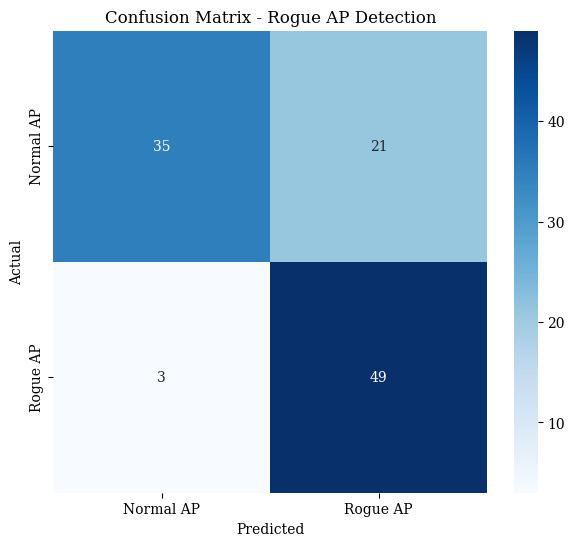

In [478]:
cm = confusion_matrix(y_test,test_preds,labels=[NORMAL_LABEL,ROGUE_LABEL])
plt.figure(figsize=(7, 6))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["Normal AP","Rogue AP"],yticklabels=["Normal AP","Rogue AP"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Rogue AP Detection")
plt.show()

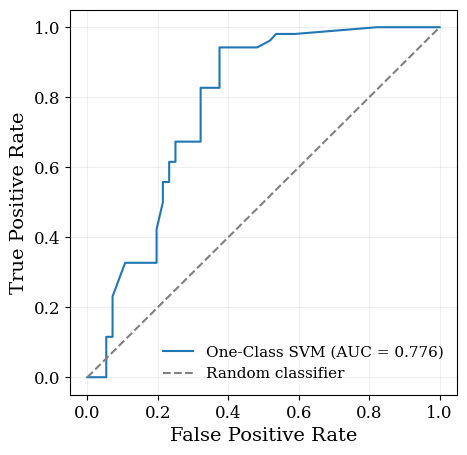

ROC AUC (Rogue AP): 0.7761


In [479]:

from sklearn.metrics import roc_curve, auc
rogue_scores = -test_scores

svm_fpr, svm_tpr, thresholds = roc_curve(y_test,rogue_scores,pos_label=ROGUE_LABEL)
auc_svm = auc(svm_fpr, svm_tpr)
plt.figure(figsize=(5, 5), dpi=100)

plt.plot(svm_fpr,svm_tpr,linestyle='-',label=f'One-Class SVM (AUC = {auc_svm:.3f})')
plt.plot([0, 1], [0, 1],linestyle='--',color='gray',label='Random classifier')

plt.xlabel('False Positive Rate', size=14)
plt.ylabel('True Positive Rate', size=14)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']

plt.legend(loc='lower right',fontsize=11,frameon=False)

plt.yticks(size=12)
plt.xticks(size=12)
plt.grid(alpha=0.2)

plt.savefig("ROCSVM.pdf",format="pdf",bbox_inches="tight")
plt.show()
print(f"ROC AUC (Rogue AP): {auc_svm:.4f}")
